## Import and subjects

In [36]:
import mne
from anlffr.helper import biosemi2mne as bs
import sys
import warnings
from anlffr.preproc import find_blinks
from matplotlib import pyplot as plt
from mne import compute_proj_epochs
from mne import concatenate_epochs
import pylab as pl
import numpy as np
import fnmatch
import os

In [37]:
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42  
plt.rcParams['svg.fonttype'] = 'none'

In [38]:
HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL011', 'HL018', 'HL023', 'HL025', 'HL031', 'HL040', 'HL045', 'HL046', 'HL048', 'HL049', 'HL047', 'HL050']
NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012', 'SP013', 'SP014','SP016', 'SP017', 'SP019', 'HL017', 'HL029', 'HL036', 'HR']

fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/'
# subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL010', 'HL011', 'HL018', 'HL021','HL023', 'HL025', 'HL031', 'HL040', 'SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'SP010', 'SP012','SP013', 'HL017', 'HL029', 'HL036' 'HR']
# subjects = ['HL025', 'HL029', 'HL031','SP010'] 

In [39]:
print(len(HL_subjects))
print(len(NH_subjects))

17
17


In [5]:
# resultsdir = 'results/'

# # subjects = ['HL045', 'HL046', 'HL048', 'HL049', 'SP013', 'SP014','SP019',]

# for subj in subjects:
#     print(subj)
#     leads = []
#     lags = []
    
#     channels_to_drop = ['GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']
    
#     bdfs = fnmatch.filter(os.listdir(fpath), subj + '_Att*.bdf')
#     print(bdfs)
    
#     for k, bdf in enumerate(bdfs):
#         if bdf == 'HL008_AttentionTask+004.bdf':
#             bdf_fullpath = os.path.join(fpath, bdf)
#             raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
#             total = raw.times[-1]
#             end_time = total - 120
#             raw = raw.crop(tmin=0, tmax=end_time)
#         else:
#             bdf_fullpath = os.path.join(fpath, bdf)
#             raw, eves = bs.importbdf(bdf_fullpath, hptsname='biosemi10_20.hpts')
#         print(f'Running file: {bdf}')
#         raw.notch_filter(np.arange(60, 241, 60), filter_length='auto', fir_design='firwin')
#         raw.filter(2, 40)

#         if subj == 'SP004' or subj == 'SP019':
#             raw.drop_channels(channels_to_drop)

#         blinks = find_blinks(raw, ch_name=['Fp1'])
#         if subj in ['HR', 'SP004', 'HL004', 'HL010', 'HL022', 'HL031']:
#             if k == 0:
#                 epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#                 blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=2)
            
#             raw.add_proj(blink_proj)
#             #raw.del_proj(1)
#             raw.apply_proj()
        
#         elif subj == 'HL022':
#             if k == 0:
#                 epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#                 blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=4)
            
#             raw.add_proj(blink_proj)
#             raw.del_proj(1)
#             raw.del_proj(2)
#             raw.apply_proj()

#         else:
#             if k == 0:
#                 epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
#                                         reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
#                 blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
            
#             raw.add_proj(blink_proj)
#             raw.del_proj(1)
#             raw.apply_proj()
    
#         events_lead = [7,9]
#         events_lead_use = [event_lead for event_lead in events_lead if event_lead in eves[:,2]]
        
#         events_lag = [8,10]
#         events_lag_use = [event_lag for event_lag in events_lag if event_lag in eves[:,2]]
    
#         if events_lead_use:
#             epochs_lead = mne.Epochs(raw, eves, event_id=events_lead_use, baseline=(-0.5, 0.0), proj=True,
#                             tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
#         if events_lag_use:
#             epochs_lag = mne.Epochs(raw, eves, event_id=events_lag_use, baseline=(-0.5, 0.0), proj=True,
#                             tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))
#         leads += [epochs_lead, ]
#         lags += [epochs_lag, ]
    
#     lead = concatenate_epochs(leads)
#     lag = concatenate_epochs(lags)    

#     evoked_lead = lead.average()
#     evoked_lag = lag.average()

#     fname_left = fpath+resultsdir+subj + '_evoked_lead_ave2.fif'
#     fname_right = fpath+resultsdir+subj + '_evoked_lag_ave2.fif'

#     evoked_lead.save(fname_left,overwrite=True)
#     evoked_lag.save(fname_right, overwrite=True)


In [6]:
foldername = '/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/Figures/'

### Evoked NH

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 82 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
   

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH

    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.49 × 7 + 0.51 × 9)
        0 CTF compensation matrices available
        nave = 80 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP013_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.50 × 7 + 0.50 × 9)
        0 CTF compensation matrices available
        nave = 82 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP013_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP014_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH

    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 81 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL036_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.49 × 7 + 0.51 × 9)
        0 CTF compensation matrices available
        nave = 76 - aspect type = 100
Projections have alre

...

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:12: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lead_NH = mne.grand_average(evoked_lead_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:12: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lead_NH = mne.grand_average(evoked_lead_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:12: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lead_NH = mne.grand_average(evoked_lead_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:12: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lead_NH = mne.grand_average(evoked_lead_NH)
/var/folders/96/xl

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Compu

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs05

Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: hea

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/2582828006.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)
/var/folders/96/xlfq_txs05

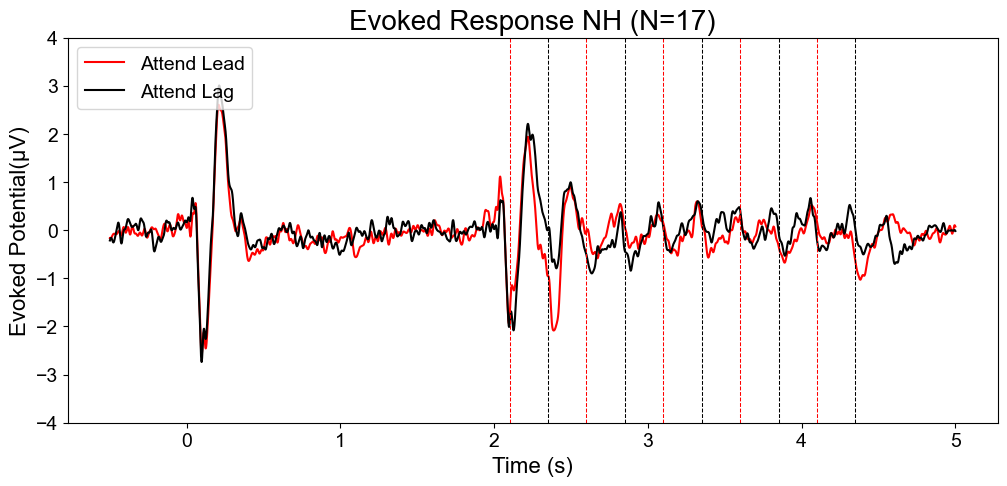

In [7]:
evoked_leads_NH = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in NH_subjects]
evoked_lags_NH = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in NH_subjects]

base_path = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/"

evoked_leads_1_NH = [base_path + filename for filename in evoked_leads_NH]
evoked_lags_1_NH = [base_path + filename for filename in evoked_lags_NH]

evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]

average_evoked_lead_NH = mne.grand_average(evoked_lead_NH)
average_evoked_lag_NH = mne.grand_average(evoked_lag_NH)

x_NH = average_evoked_lead_NH.data*1e6
y_NH = average_evoked_lag_NH.data*1e6

sum_x = 0
sum_y = 0
for i in [30,31,4,25]:
    sum_x += x_NH[i,]
    sum_y += y_NH[i,]
z = np.asarray((sum_x/4, sum_y/4))
time = np.linspace(-0.5, 5, x_NH.shape[1])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(time, z[0], linewidth=1.5, color='red', label='Evoked Lead') 
ax.plot(time, z[1], linewidth=1.5, color='black', label='Evoked Lag')
# ax.axvline(x=0.4, linestyle='--', linewidth=0.75, color='blue')  
for x_val in [2.1, 2.6, 3.1, 3.6, 4.1]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='red')
for x_val in [2.35, 2.85, 3.35, 3.85, 4.35]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='black')
ax.set_xlabel('Time (s)', fontsize=16)
ax.set_ylabel('Evoked Potential(µV)', fontsize=16)
ax.set_ylim(-4,4)
ax.tick_params(axis='both', labelsize=14)
ax.legend(['Attend Lead', 'Attend Lag'], loc='upper left', fontsize=14)
# plt.title('Evoked Response NH (N=16)', fontsize=20, color='#009e73')
plt.title('Evoked Response NH (N=17)', fontsize=20)
# plt.savefig(foldername+'Evoked_NH_newest.pdf', format='pdf')
plt.show()

Text(0, 0.5, 'Attend Lead - Attend Lag (µV)')

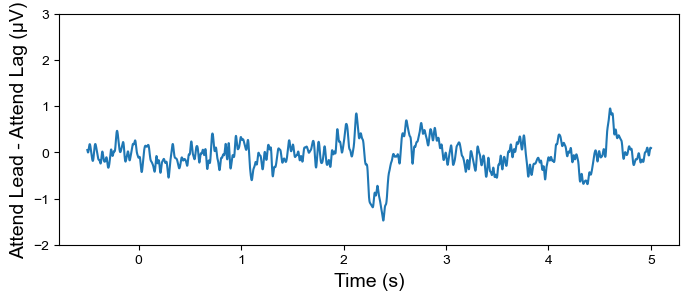

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
plt.plot(time, (z[0]-z[1]), linewidth=1.5)
plt.ylim(-2, 3)
plt.xlabel('Time (s)', fontsize=14)
plt.ylabel('Attend Lead - Attend Lag (µV)', fontsize=14) 
# ax.plot(time, z[1], linewidth=1.5, color='black', label='Evoked Lag')

### Evoked HL

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.53 × 7 + 0.47 × 9)
        0 CTF compensation matrices available
        nave = 98 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
   

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL

    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 100 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL040_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 79 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Librar

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL040_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL045_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL

    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.53 × 8 + 0.47 × 10)
        0 CTF compensation matrices available
        nave = 59 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL007_evoked_lag_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.58 × 8 + 0.42 × 10)
        0 CTF compensation matrices available
        nave = 85 - aspect type = 100
Projections have alr

...

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:13: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:13: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
/var/folders/96/xlfq_t

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Compu

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3

Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Computing interpolation matrix from 32 sensor positions
Interpolating 2 sensors
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 2.0 mm
Compu

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/252153410.py:14: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)
/var/folders/96/xlfq_txs0556r3

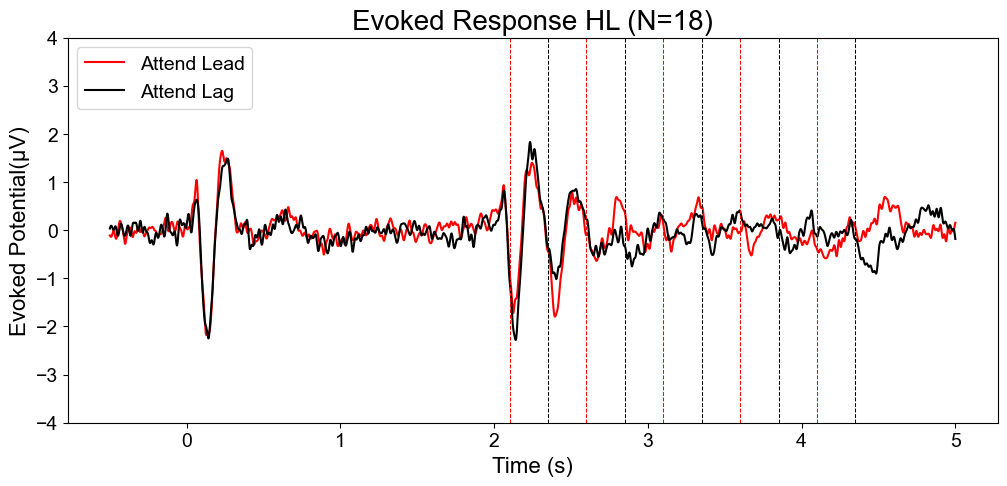

In [9]:
evoked_leads_HL = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in HL_subjects]
evoked_lags_HL = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in HL_subjects]

# base_path = '/Users/sharadhib/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/results/'
base_path = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/"

evoked_leads_1_HL = [base_path + filename for filename in evoked_leads_HL]
evoked_lags_1_HL = [base_path + filename for filename in evoked_lags_HL]

evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]

average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)

x_HL = average_evoked_lead_HL.data*1e6
y_HL = average_evoked_lag_HL.data*1e6

sum_x = 0
sum_y = 0
for i in [30,31,4,25]:
    sum_x += x_HL[i,]
    sum_y += y_HL[i,]
z = np.asarray((sum_x/4, sum_y/4))
time = np.linspace(-0.5, 5, x_HL.shape[1])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(time, z[0], linewidth=1.5, color='red', label='Evoked Lead') 
ax.plot(time, z[1], linewidth=1.5, color='black', label='Evoked Lag')  
for x_val in [2.1, 2.6, 3.1, 3.6, 4.1]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='red')
for x_val in [2.35, 2.85, 3.35, 3.85, 4.35]:
    ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='black')
ax.set_xlabel('Time (s)', fontsize=16)
ax.set_ylabel('Evoked Potential(µV)', fontsize=16)
ax.set_ylim(-4, 4)
ax.tick_params(axis='both', labelsize=14)
ax.legend(['Attend Lead', 'Attend Lag'], loc='upper left', fontsize=14)
# plt.title('Evoked Response HL (N=18)', fontsize=20, color='#CC79A7')
plt.title('Evoked Response HL (N=18)', fontsize=20)
# plt.savefig(foldername+'Evoked_HL_newest.pdf', format='pdf')
plt.show()

Text(0, 0.5, 'Attend Lead - Attend Lag (µV)')

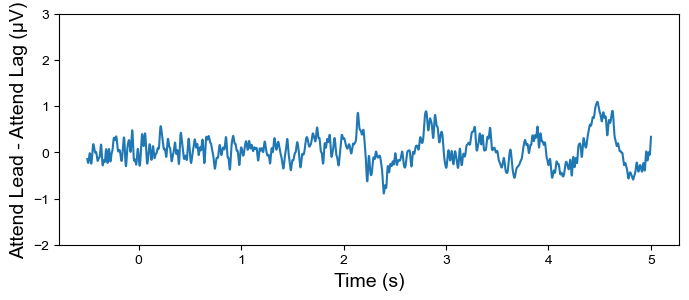

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
plt.plot(time, (z[0]-z[1]), linewidth=1.5)
plt.ylim(-2, 3)
plt.xlabel('Time (s)', fontsize=14)
plt.ylabel('Attend Lead - Attend Lag (µV)', fontsize=14) 

### All subjects evoked

In [11]:
# evoked_leads_HL = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in subjects]
# evoked_lags_HL = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in subjects]

# # base_path = '/Users/sharadhib/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/results/'
# base_path = "/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/"

# evoked_leads_1_HL = [base_path + filename for filename in evoked_leads_HL]
# evoked_lags_1_HL = [base_path + filename for filename in evoked_lags_HL]

# evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
# evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]

# average_evoked_lead_HL = mne.grand_average(evoked_lead_HL)
# average_evoked_lag_HL = mne.grand_average(evoked_lag_HL)

# x_HL = average_evoked_lead_HL.data*1e6
# y_HL = average_evoked_lag_HL.data*1e6

# sum_x = 0
# sum_y = 0
# for i in [30,31,4,25]:
#     sum_x += x_HL[i,]
#     sum_y += y_HL[i,]
# z = np.asarray((sum_x/4, sum_y/4))
# time = np.linspace(-0.5, 5, x_HL.shape[1])

# fig, ax = plt.subplots(figsize=(12, 8))
# ax.plot(time, z[0], linewidth=1.5, color='red', label='Evoked Lead') 
# ax.plot(time, z[1], linewidth=1.5, color='black', label='Evoked Lag')  
# for x_val in [2.1, 2.6, 3.1, 3.6, 4.1]:
#     ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='red')
# for x_val in [2.35, 2.85, 3.35, 3.85, 4.35]:
#     ax.axvline(x=x_val, linestyle='--', linewidth=0.75, color='black')
# ax.set_xlabel('Time (s)', fontsize=14)
# ax.set_ylabel('Evoked Potential(µV)', fontsize=14)
# ax.legend(['Attend Lead', 'Attend Lag'], loc='upper left')
# plt.show()

# RMS

### RMS indidvidual subjects

In [12]:
evoked_leads_NH = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in NH_subjects]
evoked_lags_NH = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in NH_subjects]

base_path = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/'

evoked_leads_1_NH = [base_path + filename for filename in evoked_leads_NH]
evoked_lags_1_NH = [base_path + filename for filename in evoked_lags_NH]

evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]

evoked_crop_lead_NH = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lead_NH]
evoked_crop_lag_NH = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lag_NH]

selected_channels = [30, 31, 4, 25]

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 82 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
   

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/1547622445.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/1547622445.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH

    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.50 × 7 + 0.50 × 9)
        0 CTF compensation matrices available
        nave = 148 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lag_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.50 × 8 + 0.50 × 10)
        0 CTF compensation matrices available
        nave = 68 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Librar

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/1547622445.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP003_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/1547622445.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/SP004_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]
/var/f

Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HR_evoked_lag_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.50 × 8 + 0.50 × 10)
        0 CTF compensation matrices available
        nave = 149 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)


/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/1547622445.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HR_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]


In [13]:
evoked_leads_HL = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in HL_subjects]
evoked_lags_HL = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in HL_subjects]

base_path = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/'

evoked_leads_1_HL = [base_path + filename for filename in evoked_leads_HL]
evoked_lags_1_HL = [base_path + filename for filename in evoked_lags_HL]

evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]

evoked_crop_lead_HL = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lead_HL]
evoked_crop_lag_HL = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lag_HL]

selected_channels = [30, 31, 4, 25]

Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.53 × 7 + 0.47 × 9)
        0 CTF compensation matrices available
        nave = 98 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-02 (1 x 32) active
   

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL

Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL011_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.50 × 7 + 0.50 × 9)
        0 CTF compensation matrices available
        nave = 74 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL018_evoked_lead_ave2.fif ...
    Read a 

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL011_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:9: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL018_evoked_lead_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lead_HL = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_HL

        t =    -500.00 ...    5000.00 ms (0.51 × 7 + 0.49 × 9)
        0 CTF compensation matrices available
        nave = 79 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL045_evoked_lead_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.42 × 7 + 0.58 × 9)
        0 CTF compensation matrices available
        nave = 66 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLib

...

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL002_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL004_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/f

Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL021_evoked_lag_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.54 × 8 + 0.46 × 10)
        0 CTF compensation matrices available
        nave = 54 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL023_evoked_lag_ave2.fif ...
    Read a t

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL021_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL023_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/f

    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.58 × 8 + 0.42 × 10)
        0 CTF compensation matrices available
        nave = 69 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Loaded Evoked data is baseline-corrected (baseline: [-0.5, 0] s)
Reading /Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL048_evoked_lag_ave2.fif ...
    Read a total of 2 projection items:
        eeg-998--0.250-0.250-PCA-01 (1 x 32) active
        eeg-998--0.250-0.250-PCA-03 (1 x 32) active
    Found the data of interest:
        t =    -500.00 ...    5000.00 ms (0.56 × 8 + 0.44 × 10)
        0 CTF compensation matrices available
        nave = 66 - aspect type = 100
Projections have alr

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL048_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_3993/3968461188.py:10: RuntimeWarning: This filename (/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/HL049_evoked_lag_ave2.fif) does not conform to MNE naming conventions. All evoked files should end with -ave.fif, -ave.fif.gz, _ave.fif or _ave.fif.gz
  evoked_lag_HL = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_HL]
/var/f

In [14]:
evoked_crop_lead_NH[1].data

array([[ 1.14758484e-06,  1.14052727e-06,  1.13344515e-06, ...,
         7.79141658e-07,  7.77655544e-07,  7.76085528e-07],
       [-3.82194543e-08, -3.77490821e-08, -3.72580438e-08, ...,
         2.02057009e-07,  2.00698409e-07,  1.99324134e-07],
       [ 8.10905192e-07,  8.07956269e-07,  8.04906620e-07, ...,
        -2.07665565e-07, -2.02443687e-07, -1.97239842e-07],
       ...,
       [-1.53167309e-06, -1.53047893e-06, -1.52921984e-06, ...,
        -1.43893971e-07, -1.43948824e-07, -1.43985190e-07],
       [ 7.33184550e-07,  7.42743339e-07,  7.52219705e-07, ...,
         6.20698756e-07,  6.23128358e-07,  6.25531982e-07],
       [-7.33184550e-07, -7.42743339e-07, -7.52219705e-07, ...,
        -6.20698756e-07, -6.23128358e-07, -6.25531982e-07]])

In [15]:
# individual_RMS = ((evoked_crop_lead_NH[1].data - evoked_crop_lag_NH[1].data)**2)/ ((evoked_crop_lead_NH[1].data ** 2 + evoked_crop_lag_NH[1].data ** 2) / 2)

# NH_individual_RMS = np.mean(individual_RMS[selected_channels])
# NH_individual_RMS

NH_individual_RMS = []
for i in range(len(NH_subjects)):
    RMS_num = ((evoked_crop_lead_NH[i].data - evoked_crop_lag_NH[i].data)**2)
    RMS_den = ((evoked_crop_lead_NH[i].data ** 2 + evoked_crop_lag_NH[i].data ** 2) / 2)
    RMS_central = RMS_num[selected_channels].mean()/RMS_den[selected_channels].mean()
    # RMS_central = np.mean(RMS)
    NH_individual_RMS.append(RMS_central)

NH_individual_RMS = np.array(NH_individual_RMS)

In [16]:
HL_individual_RMS = []
for i in range(len(HL_subjects)):
    RMS_num = ((evoked_crop_lead_HL[i].data - evoked_crop_lag_HL[i].data)**2)
    RMS_den = ((evoked_crop_lead_HL[i].data ** 2 + evoked_crop_lag_HL[i].data ** 2) / 2)
    RMS_central = RMS_num[selected_channels].mean()/RMS_den[selected_channels].mean()
    # RMS_central = np.mean(RMS)
    HL_individual_RMS.append(RMS_central)

HL_individual_RMS = np.array(HL_individual_RMS)

In [17]:
print(NH_individual_RMS.mean(), HL_individual_RMS.mean())

1.4791371217031828 1.6852488183519088


In [18]:
x = NH_individual_RMS.astype(float)
n = x.size

NH_loo_means = np.array([x[np.arange(n) != i].mean() for i in range(n)])
NH_theta_dot = NH_loo_means.mean()
NH_jack_var = (n - 1) / n * np.sum((NH_loo_means - NH_theta_dot) ** 2)
NH_jack_se = np.sqrt(NH_jack_var)

In [19]:
x = HL_individual_RMS.astype(float)
n = x.size

HL_loo_means = np.array([x[np.arange(n) != i].mean() for i in range(n)])
HL_theta_dot = HL_loo_means.mean()
HL_jack_var = (n - 1) / n * np.sum((HL_loo_means - HL_theta_dot) ** 2)
HL_jack_se = np.sqrt(HL_jack_var)

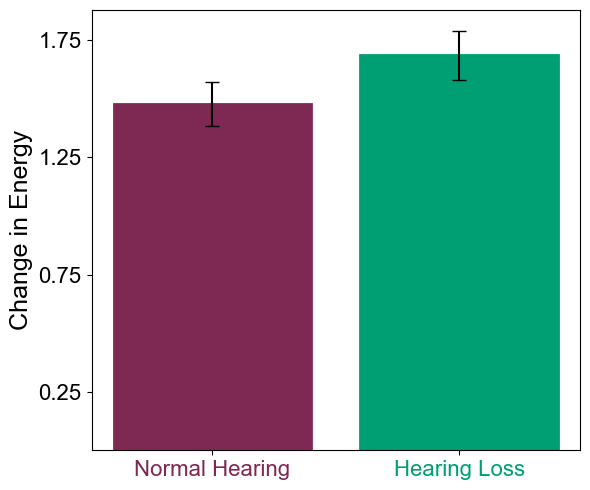

In [20]:
x_labels = ["Normal Hearing", "Hearing Loss"]
x_positions = np.arange(len(x_labels))

# Example values (replace with your actual data)
mean_changes = [NH_individual_RMS.mean(), HL_individual_RMS.mean()]
sem_values = [NH_jack_se, HL_jack_se]

# plt.figure(figsize=(7, 5))
# bars = plt.bar(x_positions, mean_changes, yerr=sem_values, capsize=5, color='gray', edgecolor='black')

# plt.xticks(x_positions, x_labels)
# plt.ylabel("Change in Energy", fontsize=14)
# # plt.yticks(np.arange))
# plt.ylim([0.00,2])
# # plt.ylim(60, 100)
# plt.tick_params(axis='x', labelsize=12)
# plt.tick_params(axis='y', labelsize=12)
# plt.title("Attentional Modulation of Evoked Responses", fontsize=16)

# # plt.savefig(foldername + 'RMS_evoked_bar.pdf', format='pdf')
# plt.tight_layout()
# plt.show()

plt.figure(figsize=(6, 5))
bars = plt.bar(
    x_positions,
    mean_changes,
    yerr=sem_values,
    capsize=5,
    color='white',
    edgecolor='black',
    linewidth=2
)

# Normal Hearing
bars[0].set_edgecolor('#7E2954')
bars[0].set_facecolor('#7E2954')  # wine

# Hearing Loss
bars[1].set_edgecolor('#009E73')
bars[1].set_facecolor('#009E73')  # green

plt.yticks([0.25, 0.75, 1.25, 1.75])

plt.xticks(x_positions, x_labels)
plt.ylabel("Change in Energy", fontsize=18)
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)
# plt.title("Attentional Modulation of Evoked Responses", fontsize=20)

# Color x-tick labels
ax = plt.gca()
xtick_labels = ax.get_xticklabels()
xtick_labels[0].set_color('#7E2954')
xtick_labels[1].set_color('#009E73')

plt.tight_layout()
plt.show()

### RMS done

In [21]:
# evoked_leads_NH = [f'{subject_id}_evoked_lead_ave2.fif' for subject_id in NH_subjects]
# evoked_lags_NH = [f'{subject_id}_evoked_lag_ave2.fif' for subject_id in NH_subjects]

# base_path = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/'

# evoked_leads_1_NH = [base_path + filename for filename in evoked_leads_NH]
# evoked_lags_1_NH = [base_path + filename for filename in evoked_lags_NH]

# evoked_lead_NH = [mne.read_evokeds(leads)[0] for leads in evoked_leads_1_NH]
# evoked_lag_NH = [mne.read_evokeds(lags)[0] for lags in evoked_lags_1_NH]

# evoked_crop_lead_NH = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lead_NH]
# evoked_crop_lag_NH = [evk.crop(tmin=2.35, tmax=4.35) for evk in evoked_lag_NH]

# selected_channels = [30, 31, 4, 25]

# average_evoked_lead_NH = mne.grand_average(evoked_crop_lead_NH)
# average_evoked_lag_NH = mne.grand_average(evoked_crop_lag_NH)

# print(average_evoked_lead_NH.data.shape)

# mean_squared_diff_NH = (average_evoked_lead_NH.data - average_evoked_lag_NH.data) ** 2

# mean_denominator_NH = (average_evoked_lead_NH.data ** 2 + average_evoked_lag_NH.data ** 2) / 2

# mean_squared_diff_avg_NH = np.mean(mean_squared_diff_NH[selected_channels])
# mean_denominator_avg_NH = np.mean(mean_denominator_NH[selected_channels])

# mean_normalized_change_NH = mean_squared_diff_avg_NH / mean_denominator_avg_NH

# change_loo_gavg_NH = []
# normalized_change_loo_gavg_NH = []
# S = len(NH_subjects)

# for i in range(len(NH_subjects)):
#     loo_subset_leads_NH = evoked_crop_lead_NH[:i] + evoked_crop_lead_NH[i+1:]
#     loo_subset_lags_NH = evoked_crop_lag_NH[:i] + evoked_crop_lag_NH[i+1:]

#     loo_average_evoked_lead_NH = mne.grand_average(loo_subset_leads_NH)
#     loo_average_evoked_lag_NH = mne.grand_average(loo_subset_lags_NH)

#     squared_diff = (loo_average_evoked_lead_NH.data - loo_average_evoked_lag_NH.data) ** 2

#     denominator = (loo_average_evoked_lead_NH.data ** 2 + loo_average_evoked_lag_NH.data ** 2) / 2

#     squared_diff_avg = np.mean(squared_diff[selected_channels])
#     denominator_avg = np.mean(denominator[selected_channels])

#     normalized_change_loo = np.sqrt(squared_diff_avg) / np.sqrt(denominator_avg)

#     normalized_change_loo_gavg_NH.append(normalized_change_loo)

# loo_normalized_change_gavg_NH_var = np.var(normalized_change_loo_gavg_NH)
# loo_normalized_change_gavg_NH_std = np.sqrt(loo_normalized_change_gavg_NH_var)
# loo_normalized_change_gavg_NH_sem = loo_normalized_change_gavg_NH_std / np.sqrt(len(NH_subjects))

# # jackknife_mean_NH = np.mean(normalized_change_loo_gavg_NH)
# # jackknife_variance_NH = (S - 1) / S * np.sum((normalized_change_loo_gavg_NH - jackknife_mean_NH) ** 2)
# # jackknife_std_NH = np.sqrt(jackknife_variance_NH)
# # jackknife_sem_NH = jackknife_std_NH / np.sqrt(S)

# Alpha wave stuff

### Load spectrogram data

In [40]:
res_fpath = '/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/'
# HL_subjects = ['HL002', 'HL004', 'HL005', 'HL007', 'HL008', 'HL010', 'HL017', 'HL018', 'HL021','HL023']
# NH_subjects = ['SP003', 'SP004', 'SP005', 'SP006', 'SP007', 'SP008' , 'HR']

In [41]:
# file = '_norm_right_left_preprestim.npy'
file = '_norm_right_left_alphaIndividual.npy'
# file_dur = '_norm_right_left_dur.npy'

HL_sum_right_left_pre = np.zeros(32)
# HL_sum_right_left_dur = np.zeros(32)

NH_sum_right_left_pre = np.zeros(32)
# NH_sum_right_left_dur = np.zeros(32)

for subj in HL_subjects:
    print(res_fpath+subj+file)
    left_right_pre = np.load(res_fpath+subj+file)
    # left_right_dur = np.load(res_fpath+subj+file_dur)
    HL_sum_right_left_pre += left_right_pre
    # HL_sum_right_left_dur += left_right_dur
    
HL_avg_right_left_pre = HL_sum_right_left_pre/len(HL_subjects)
# HL_avg_right_left_dur = HL_sum_right_left_dur/len(HL_subjects)



/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/HL002_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/HL004_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/HL005_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/HL007_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD 

In [42]:
for sub in NH_subjects:
    print(res_fpath+sub+file)
    left_right_pre = np.load(res_fpath+sub+file)
    # left_right_dur = np.load(res_fpath+sub+file_dur)
    NH_sum_right_left_pre += left_right_pre
    # NH_sum_right_left_dur += left_right_dur
    
NH_avg_right_left_pre = NH_sum_right_left_pre/len(NH_subjects)
# NH_avg_right_left_dur = NH_sum_right_left_dur/len(NH_subjects)

/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/SP003_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/SP004_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/SP005_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/resultsApr2026_PSD_IndividualAlpha/SP006_norm_right_left_alphaIndividual.npy
/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD 

#### Load info

In [35]:
raw, eves = bs.importbdf('/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/HL004_AttentionTask+001.bdf', hptsname='/Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/biosemi10_20.hpts')
# raw, eves = bs.importbdf('/Users/sharadhib/Library/CloudStorage/Box-Box/SNAPlab/Data/SP003_Att+001.bdf', hptsname='/Users/sharadhib/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/biosemi10_20.hpts')
raw.notch_filter(np.arange(60, 241, 60), filter_length='auto', fir_design='firwin')
raw.filter(1, 20)

blinks = find_blinks(raw, ch_name=['Fp1'])
epochs_blinks = mne.Epochs(raw, blinks, event_id=998, baseline=(-0.25, 0.25),
                             reject=dict(eeg=500e-6), tmin=-0.25, tmax=0.25)
blink_proj = compute_proj_epochs(epochs_blinks, n_eeg=3)
raw.add_proj(blink_proj)
raw.del_proj(1)
epochs_left = mne.Epochs(raw, eves, event_id=[7,8], baseline=(-0.5, 0), proj=True,
                        tmin=-0.5, tmax=5, reject=dict(eeg=200e-6))

Extracting BDF parameters from /Users/SHB330/Library/CloudStorage/OneDrive-UniversityofPittsburgh/Attachments/Attention_EEG/HL004_AttentionTask+001.bdf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8716287  =      0.000 ...   532.000 secs...
Re-referencing data to: EXG1 EXG2EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65280 (consider using initial_event=True to detect this event)
109 events found on stim channel Status
Event IDs: [ 4  5  7  8  9 10 11]
Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter len

In [43]:
epochs_left

<Epochs | 19 events (good & bad), -0.5 – 5 s (baseline -0.5 – 0 s), ~53 KiB, data not loaded,
 '7': 8
 '8': 11>

In [44]:
channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','Pz','PO3',
 'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']

epoch_pre_left = epochs_left.copy().load_data().crop(tmin=0.4, tmax=2.0)
epoch_dur_left = epochs_left.copy().load_data().crop(tmin=2.0, tmax=5.0)

info_pre_picked = mne.pick_info(epochs_left.info, mne.pick_channels(epochs_left.info['ch_names'], include =channels))
info_dur_picked = mne.pick_info(epochs_left.info, mne.pick_channels(epochs_left.info['ch_names'], include =channels))

Using data from preloaded Raw for 19 events and 90113 original time points ...
    Rejecting  epoch based on EEG : ['F3']
1 bad epochs dropped
Using data from preloaded Raw for 19 events and 90113 original time points ...
    Rejecting  epoch based on EEG : ['F3']
1 bad epochs dropped


### Plot Pre

#### HL

Approximating Fpz location by mirroring Oz along the X and Y axes.


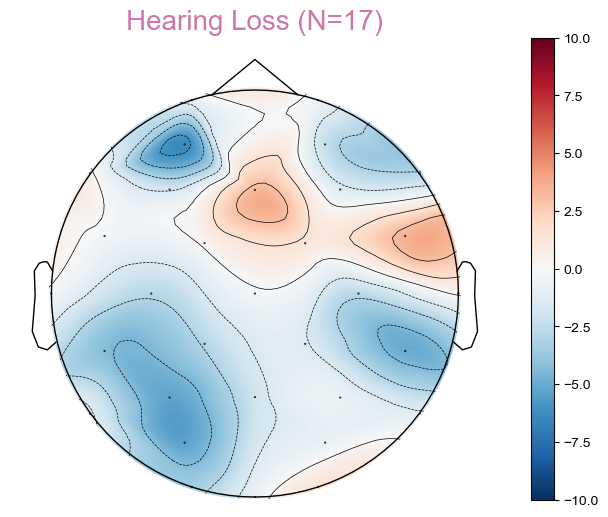

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))
channels = ['Fp1','AF3','F7','F3','FC1','FC5','T7','C3','CP1','CP5','P7','P3','PO3',
                'O1','Oz','O2','PO4','P4','P8','CP6','CP2','C4','T8','FC6','FC2','F4','F8','AF4','Fp2','Fz','Cz']
im,_ = mne.viz.plot_topomap(HL_avg_right_left_pre, info_pre_picked, vlim=(-10,10), axes=ax, ch_type='eeg',show=False, sphere='eeglab')
plt.colorbar(im, ax=ax)
plt.title('Hearing Loss (N=17)', fontsize=20, color='#CC79A7')
# plt.savefig(foldername+'HL_preStim_613.pdf', format='pdf')
plt.show()

#### NH

Approximating Fpz location by mirroring Oz along the X and Y axes.


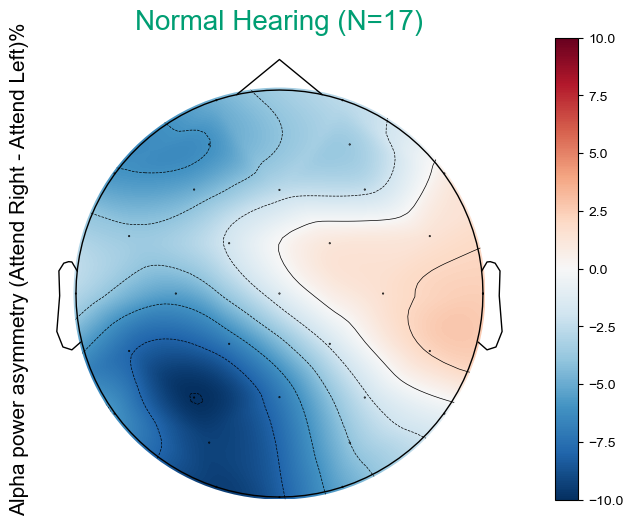

In [46]:
fig, ax = plt.subplots(figsize=(8, 6))
im,_ = mne.viz.plot_topomap(NH_avg_right_left_pre, info_pre_picked, vlim=(-10,10), axes=ax, ch_type='eeg',show=False,sphere='eeglab')
plt.colorbar(im, ax=ax)
plt.title('Normal Hearing (N=17)', fontsize=20, color='#009e73')
plt.ylabel('Alpha power asymmetry (Attend Right - Attend Left)%', fontsize=15)
# plt.savefig(foldername+'NH_preStim_613.pdf', format='pdf')
plt.show()

### All subjects alpha pre

/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5603/1270900186.py:4: RuntimeWarning: Only 6 head digitization points of the specified kind ("extra",), fitting may be inaccurate
  im,_ = mne.viz.plot_topomap(avg_right_left_pre, info_pre_picked, vlim=(-8,8),  axes=ax, ch_type='eeg',show=False)
/var/folders/96/xlfq_txs0556r3zlvt2nccfr0000gp/T/ipykernel_5603/1270900186.py:4: RuntimeWarning: Estimated head radius (0.2 cm) is below the 3rd percentile for infant head size.
  im,_ = mne.viz.plot_topomap(avg_right_left_pre, info_pre_picked, vlim=(-8,8),  axes=ax, ch_type='eeg',show=False)


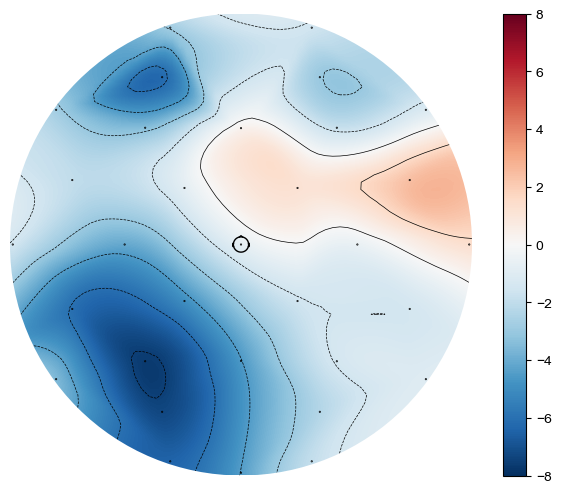

In [47]:
avg_right_left_pre = (NH_avg_right_left_pre + HL_avg_right_left_pre)/2

fig, ax = plt.subplots(figsize=(8, 6))
im,_ = mne.viz.plot_topomap(avg_right_left_pre, info_pre_picked, vlim=(-8,8),  axes=ax, ch_type='eeg',show=False)
plt.colorbar(im, ax=ax)
plt.show()

### Plot During

#### NH

In [48]:
# fig, ax = plt.subplots(figsize=(8, 6))
# im,_ = mne.viz.plot_topomap(NH_avg_right_left_dur, info_pre_picked, vlim=(-8,8), axes=ax, ch_type='eeg',show=False)
# plt.colorbar(im, ax=ax)
# # plt.savefig(foldername+'NH_durStim_613.pdf', format='pdf')
# plt.show()

#### HL

In [49]:
# fig, ax = plt.subplots(figsize=(8, 6))
# im,_ = mne.viz.plot_topomap(HL_avg_right_left_dur, info_pre_picked, vlim=(-8,8),  axes=ax, ch_type='eeg',show=False)
# plt.colorbar(im, ax=ax)
# # plt.savefig(foldername+'HL_durStim_613.pdf', format='pdf')
# plt.show()

### All subjects alpha during 

In [50]:
# avg_right_left_dur = (HL_avg_right_left_dur + NH_avg_right_left_dur)/2

# fig, ax = plt.subplots(figsize=(8, 6))
# im,_ = mne.viz.plot_topomap(avg_right_left_dur, info_pre_picked, vlim=(-8,8), names=channels,  axes=ax, ch_type='eeg',show=False)
# plt.colorbar(im, ax=ax)
# plt.show()

## Assymetry 

### Parieto-occipital

In [51]:
PO_left = [10,11,13,14]
PO_right = [19,18,17,16]

NH_assymetry_pre = np.mean(NH_avg_right_left_pre[PO_right] - NH_avg_right_left_pre[PO_left])

# NH_assymtery_dur = np.mean(NH_avg_right_left_dur[PO_right] - NH_avg_right_left_dur[PO_left])

HL_assymetry_pre = np.mean(HL_avg_right_left_pre[PO_right] - HL_avg_right_left_pre[PO_left])

# HL_assymtery_dur = np.mean(HL_avg_right_left_dur[PO_right] - HL_avg_right_left_dur[PO_left])

In [52]:
file = '_norm_right_left_alphaIndividual.npy'
# file_dur = '_norm_right_left_dur.npy'

NH_assymetry_PO_pre = []
# NH_assymetry_PO_dur = []
for subj in NH_subjects:
    left_right_pre = np.load(res_fpath+subj+file)
    # left_right_dur = np.load(res_fpath+subj+file_dur)
    NH_sub_assymetry_PO_pre = np.mean(left_right_pre[PO_right] - left_right_pre[PO_left])
    # NH_sub_assymetry_PO_dur = np.mean(left_right_dur[PO_right] - left_right_dur[PO_left])
    NH_assymetry_PO_pre.append(NH_sub_assymetry_PO_pre)
    # NH_assymetry_PO_dur.append(NH_sub_assymetry_PO_dur)

NH_assymetry_PO_pre = np.array(NH_assymetry_PO_pre)
# NH_assymetry_PO_dur = np.array(NH_assymetry_PO_dur)

In [53]:
HL_assymetry_PO_pre = []
# HL_assymetry_PO_dur = []
for subj in HL_subjects:
    left_right_pre = np.load(res_fpath+subj+file)
    # left_right_dur = np.load(res_fpath+subj+file_dur)
    HL_sub_assymetry_PO_pre = np.mean(left_right_pre[PO_right] - left_right_pre[PO_left])
    # HL_sub_assymetry_PO_dur = np.mean(left_right_dur[PO_right] - left_right_dur[PO_left])
    HL_assymetry_PO_pre.append(HL_sub_assymetry_PO_pre)
    # HL_assymetry_PO_dur.append(HL_sub_assymetry_PO_dur)

HL_assymetry_PO_pre = np.array(HL_assymetry_PO_pre)
# HL_assymetry_PO_dur = np.array(HL_assymetry_PO_dur)

In [54]:
NH_assymetry_PO_pre_var = np.var(NH_assymetry_PO_pre)
NH_assymetry_PO_pre_std = np.sqrt(NH_assymetry_PO_pre_var)
NH_assymetry_PO_pre_sem = NH_assymetry_PO_pre_std / np.sqrt(len(NH_subjects))

# NH_assymetry_PO_dur_var = np.var(NH_assymetry_PO_dur)
# NH_assymetry_PO_dur_std = np.sqrt(NH_assymetry_PO_dur_var)
# NH_assymetry_PO_dur_sem = NH_assymetry_PO_dur_std / np.sqrt(len(NH_subjects))

HL_assymetry_PO_pre_var = np.var(HL_assymetry_PO_pre)
HL_assymetry_PO_pre_std = np.sqrt(HL_assymetry_PO_pre_var)
HL_assymetry_PO_pre_sem = HL_assymetry_PO_pre_std / np.sqrt(len(HL_subjects))

# HL_assymetry_PO_dur_var = np.var(HL_assymetry_PO_dur)
# HL_assymetry_PO_dur_std = np.sqrt(HL_assymetry_PO_dur_var)
# HL_assymetry_PO_dur_sem = HL_assymetry_PO_dur_std / np.sqrt(len(HL_subjects))

In [55]:
sem_values = [NH_assymetry_PO_pre_sem, HL_assymetry_PO_pre_sem]
sem_values

[2.4164754204594145, 2.0799460363909916]

In [56]:
NH_assymetry_PO_pre

array([ 15.61156741,  -4.71709664,  -0.25002959,   2.91931842,
         6.60507228,  -2.13343638, -14.7627594 ,  16.51975519,
         1.31124842,  28.77690262,  17.36036396,  13.23205939,
         7.16096028,   0.20445195,   6.39022497,   4.52191716,
        -2.11109469])

In [57]:
# [np.mean(NH_assymetry_PO_dur), np.mean(HL_assymetry_PO_dur)]

In [58]:
def mad(x):
    med = np.median(x)
    n = x.shape[0]
    return (np.median(np.abs(x - med))/np.sqrt(n))

1.6087416761879252
1.3203128989222246


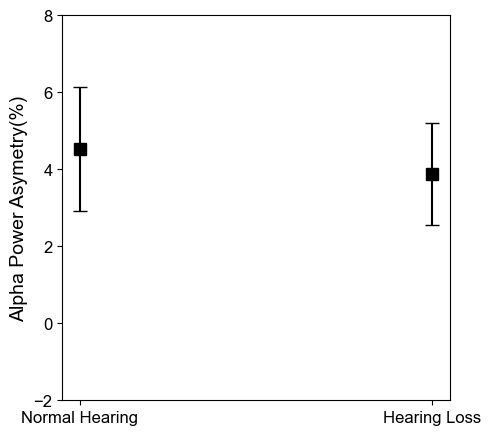

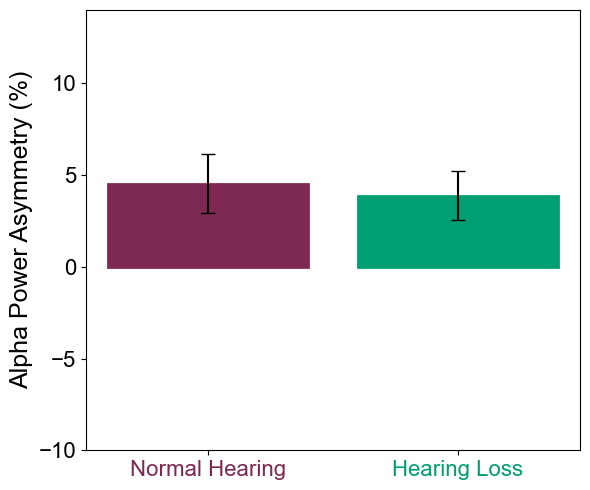

In [59]:
x_labels = ["Normal Hearing", "Hearing Loss"] 
x_positions = np.arange(len(x_labels))

mean_changes = [np.median(NH_assymetry_PO_pre), np.median(HL_assymetry_PO_pre)]
sem_values = [mad(NH_assymetry_PO_pre), mad(HL_assymetry_PO_pre)]
NH_assymetry_CT_pre_var = mad(NH_assymetry_PO_pre)
HL_assymetry_CT_pre_var = mad(HL_assymetry_PO_pre)

print(NH_assymetry_CT_pre_var)
print(HL_assymetry_CT_pre_var)

plt.figure(figsize=(5, 5))
plt.errorbar(x_positions, mean_changes, yerr=sem_values, fmt='s', capsize=5, color='black', markersize=8)
plt.xticks(x_positions, x_labels)  
plt.yticks([-2,0,2,4,6,8])
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

plt.ylabel("Alpha Power Asymetry(%)", fontsize=14)
plt.show()


plt.figure(figsize=(6, 5))
bars = plt.bar(
    x_positions,
    mean_changes,
    yerr=sem_values,
    capsize=5,
    color='white',
    edgecolor='black',
    linewidth=2
)

# Normal Hearing
bars[0].set_edgecolor('#7E2954')
bars[0].set_facecolor('#7E2954')  # lighter teal

# Hearing Loss
bars[1].set_edgecolor('#009E73')
bars[1].set_facecolor('#009E73')  # lighter purple

# plt.yticks([0.25, 0.75, 1.25, 1.75])
plt.ylim([-10,14])

plt.xticks(x_positions, x_labels)
plt.ylabel("Alpha Power Asymmetry (%)", fontsize=18)
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)
# plt.title("Attentional Modulation of Evoked Responses", fontsize=20)

# Color x-tick labels
ax = plt.gca()
xtick_labels = ax.get_xticklabels()
xtick_labels[0].set_color('#7E2954')
xtick_labels[1].set_color('#009E73')

plt.tight_layout()
plt.show()


In [60]:
# from scipy.stats import ttest_ind_from_stats

# t_stat_pre, p_value_pre = ttest_ind_from_stats(np.mean(NH_assymetry_PO_pre), NH_assymetry_PO_pre_var**0.5, len(NH_subjects), np.mean(HL_assymetry_PO_pre), HL_assymetry_PO_pre_var**0.5, len(HL_subjects), equal_var=False)
# # t_stat_dur, p_value_dur = ttest_ind_from_stats(np.mean(NH_assymetry_PO_dur), NH_assymetry_PO_dur_var**0.5, len(NH_subjects), np.mean(HL_assymetry_PO_dur), HL_assymetry_PO_dur_var**0.5, len(HL_subjects), equal_var=False)

In [61]:
# print(p_value_pre)

### Central Parietal

In [62]:
right= [18,20,21,22,23]
left = [11,9,8,7,6]

NH_assymetry_central_pre = np.mean(NH_avg_right_left_pre[right] - NH_avg_right_left_pre[left])
HL_assymetry_central_pre = np.mean(HL_avg_right_left_pre[right] - HL_avg_right_left_pre[left])

In [63]:
HL_assymetry_central_pre

1.1805348766329047

In [64]:
# HL_assymtery_central_dur

In [65]:
file = '_norm_right_left_alphaIndividual.npy'
# file_dur = '_norm_right_left_dur.npy'

NH_assymetry_CT_pre = []
# NH_assymetry_CT_dur = []
for subj in NH_subjects:
    left_right_pre = np.load(res_fpath+subj+file)
    # left_right_dur = np.load(res_fpath+subj+file_dur)
    NH_sub_assymetry_CT_pre = np.mean(left_right_pre[right] - left_right_pre[left])
    # NH_sub_assymetry_CT_dur = np.mean(left_right_dur[right] - left_right_dur[left])
    NH_assymetry_CT_pre.append(NH_sub_assymetry_CT_pre)
    # NH_assymetry_CT_dur.append(NH_sub_assymetry_CT_dur)

NH_assymetry_CT_pre = np.array(NH_assymetry_CT_pre)
# NH_assymetry_CT_dur = np.array(NH_assymetry_CT_dur)

In [66]:
HL_assymetry_CT_pre = []
# HL_assymetry_CT_dur = []
for subj in HL_subjects:
    left_right_pre = np.load(res_fpath+subj+file)
    # left_right_dur = np.load(res_fpath+subj+file_dur)
    HL_sub_assymetry_CT_pre = np.mean(left_right_pre[right] - left_right_pre[left])
    # HL_sub_assymetry_CT_dur = np.mean(left_right_dur[right] - left_right_dur[left])
    HL_assymetry_CT_pre.append(HL_sub_assymetry_CT_pre)
    # HL_assymetry_CT_dur.append(HL_sub_assymetry_CT_dur)

HL_assymetry_CT_pre = np.array(HL_assymetry_CT_pre)
# HL_assymetry_CT_dur = np.array(HL_assymetry_CT_dur)

In [67]:
NH_assymetry_CT_pre_var = np.var(NH_assymetry_CT_pre)
NH_assymetry_CT_pre_std = np.sqrt(NH_assymetry_CT_pre_var)
NH_assymetry_CT_pre_sem = NH_assymetry_CT_pre_std / np.sqrt(len(NH_subjects))

# NH_assymetry_CT_dur_var = np.var(NH_assymetry_CT_dur)
# NH_assymetry_CT_dur_std = np.sqrt(NH_assymetry_CT_dur_var)
# NH_assymetry_CT_dur_sem = NH_assymetry_CT_dur_std / np.sqrt(len(NH_subjects))

HL_assymetry_CT_pre_var = np.var(HL_assymetry_CT_pre)
HL_assymetry_CT_pre_std = np.sqrt(HL_assymetry_CT_pre_var)
HL_assymetry_CT_pre_sem = HL_assymetry_CT_pre_std / np.sqrt(len(HL_subjects))

# HL_assymetry_CT_dur_var = np.var(HL_assymetry_CT_dur)
# HL_assymetry_CT_dur_std = np.sqrt(HL_assymetry_CT_dur_var)
# HL_assymetry_CT_dur_sem = HL_assymetry_CT_dur_std / np.sqrt(len(HL_subjects))

In [68]:
NH_HL_assymetry_CT_pre = []
NH_HL_assymetry_CT_pre = np.concatenate([np.array(NH_assymetry_CT_pre), np.array(HL_assymetry_CT_pre)])

In [69]:
from scipy.stats import shapiro
stat, p = shapiro(NH_assymetry_CT_pre)
print(f"Shapiro-Wilk p={p:.3f}")

Shapiro-Wilk p=0.007


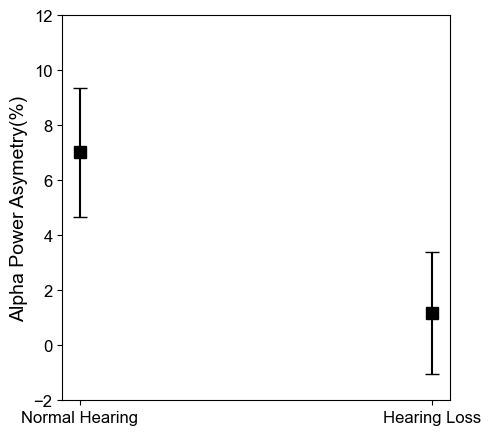

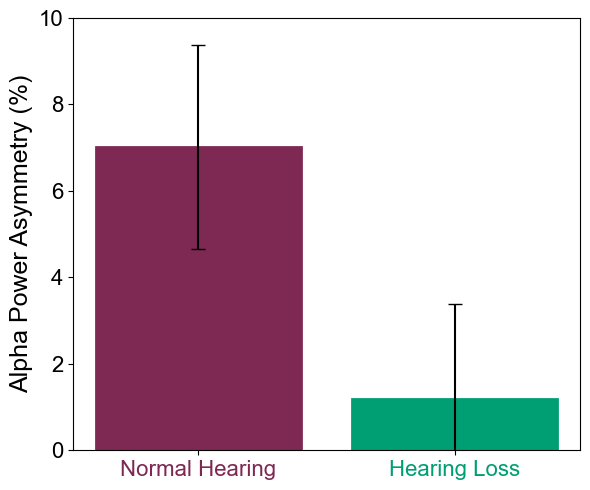

In [70]:
# x_labels = ["Normal Hearing Pre-Stim", "Normal Hearing Dur-Stim", "Hearing Loss Pre-Stim", "Hearing Loss Dur-Stim"] 
x_labels = ["Normal Hearing", "Hearing Loss"] 
x_positions = np.arange(len(x_labels))

# mean_changes = [np.mean(NH_assymetry_PO_pre), np.mean(NH_assymetry_PO_dur),np.mean(HL_assymetry_PO_pre), np.mean(HL_assymetry_PO_dur)]
# mean_changes = [np.mean(NH_assymetry_CT_pre), np.mean(HL_assymetry_CT_pre),np.mean(NH_assymetry_CT_dur), np.mean(HL_assymetry_CT_dur)]
mean_changes = [np.mean(NH_assymetry_CT_pre), np.mean(HL_assymetry_CT_pre)]
# sem_values = [NH_assymetry_PO_pre_sem, NH_assymetry_PO_dur_sem, HL_assymetry_PO_pre_sem, HL_assymetry_PO_dur_sem]
# sem_values = [NH_assymetry_CT_pre_sem, HL_assymetry_CT_pre_sem, NH_assymetry_CT_dur_sem, HL_assymetry_CT_dur_sem]
sem_values = [NH_assymetry_CT_pre_sem, HL_assymetry_CT_pre_sem]

plt.figure(figsize=(5, 5))
plt.errorbar(x_positions, mean_changes, yerr=sem_values, fmt='s', capsize=5, color='black', markersize=8)
plt.xticks(x_positions, x_labels)  
plt.yticks([-2,0,2,4,6,8,10, 12])
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

plt.ylabel("Alpha Power Asymetry(%)", fontsize=14)
# plt.title("Change in Energy during stimulus")
# plt.savefig(foldername+'alpha_power_assymetry_CT.pdf', format='pdf')
plt.show()


plt.figure(figsize=(6, 5))
bars = plt.bar(
    x_positions,
    mean_changes,
    yerr=sem_values,
    capsize=5,
    color='white',          # temporary, will override per bar
    edgecolor='black',
    linewidth=2
)

# Normal Hearing
bars[0].set_edgecolor('#7E2954')
bars[0].set_facecolor('#7E2954')  # lighter teal

# Hearing Loss
bars[1].set_edgecolor('#009E73')
bars[1].set_facecolor('#009E73')  # lighter purple

# plt.yticks([0.25, 0.75, 1.25, 1.75])
plt.ylim([0,10])

plt.xticks(x_positions, x_labels)
plt.ylabel("Alpha Power Asymmetry (%)", fontsize=18)
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)
# plt.title("Attentional Modulation of Evoked Responses", fontsize=20)

# Color x-tick labels
ax = plt.gca()
xtick_labels = ax.get_xticklabels()
xtick_labels[0].set_color('#7E2954')
xtick_labels[1].set_color('#009E73')

plt.tight_layout()
plt.show()


In [71]:
def mad(x):
    med = np.median(x)
    n = x.shape[0]
    return (np.median(np.abs(x - med))/np.sqrt(n))

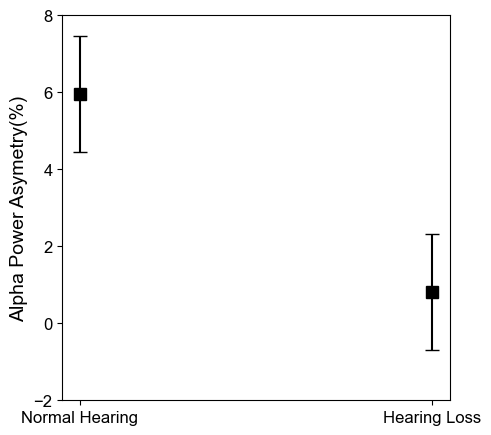

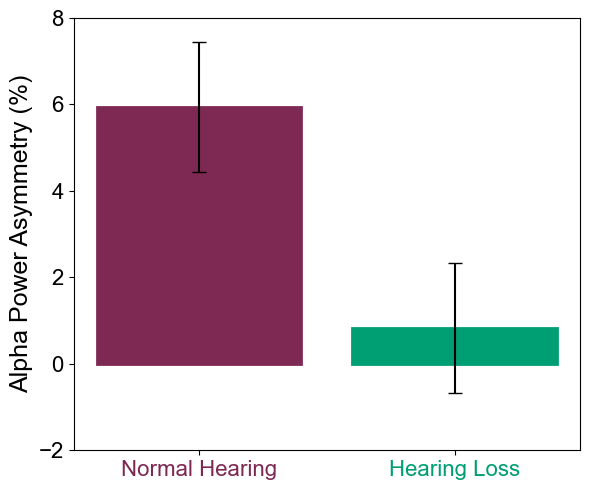

In [72]:
x_labels = ["Normal Hearing", "Hearing Loss"] 
x_positions = np.arange(len(x_labels))

mean_changes = [np.median(NH_assymetry_CT_pre), np.median(HL_assymetry_CT_pre)]
sem_values = [mad(NH_assymetry_CT_pre), mad(HL_assymetry_CT_pre)]
NH_assymetry_CT_pre_var = mad(NH_assymetry_CT_pre)
HL_assymetry_CT_pre_var = mad(HL_assymetry_CT_pre)

# print(NH_assymetry_CT_pre_var[1:5])

plt.figure(figsize=(5, 5))
plt.errorbar(x_positions, mean_changes, yerr=sem_values, fmt='s', capsize=5, color='black', markersize=8)
plt.xticks(x_positions, x_labels)  
plt.yticks([-2,0,2,4,6,8])
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)

plt.ylabel("Alpha Power Asymetry(%)", fontsize=14)
plt.show()

# plt.figure(figsize=(5, 5))

# # Normal Hearing (teal)
# plt.errorbar(
#     x_positions[0],
#     mean_changes[0],
#     yerr=sem_values[0],
#     fmt='s',
#     capsize=5,
#     color='#009e73',
#     markersize=8
# )

# # Hearing Loss (purple)
# plt.errorbar(
#     x_positions[1],
#     mean_changes[1],
#     yerr=sem_values[1],
#     fmt='s',
#     capsize=5,
#     color='#CC79A7',
#     markersize=8
# )

# plt.xticks(x_positions, x_labels)

# ax = plt.gca()
# xtick_labels = ax.get_xticklabels()

# xtick_labels[0].set_color('#009e73')  # Normal Hearing (teal)
# xtick_labels[1].set_color('#CC79A7')  # Hearing Loss (purple)

# plt.yticks([-2, 0, 2, 4, 6, 8])
# plt.tick_params(axis='x', labelsize=16)
# plt.tick_params(axis='y', labelsize=16)

# plt.ylabel("Alpha Power Asymetry (%)", fontsize=18)
# plt.show()

plt.figure(figsize=(6, 5))
bars = plt.bar(
    x_positions,
    mean_changes,
    yerr=sem_values,
    capsize=5,
    color='white',          # temporary, will override per bar
    edgecolor='black',
    linewidth=2
)

# Normal Hearing
bars[0].set_edgecolor('#7E2954')
bars[0].set_facecolor('#7E2954')  # wine

# Hearing Loss
bars[1].set_edgecolor('#009E73')
bars[1].set_facecolor('#009E73')  # green

# plt.yticks([0.25, 0.75, 1.25, 1.75])
plt.ylim([-2,8])

plt.xticks(x_positions, x_labels)
plt.ylabel("Alpha Power Asymmetry (%)", fontsize=18)
plt.tick_params(axis='x', labelsize=16)
plt.tick_params(axis='y', labelsize=16)
# plt.title("Attentional Modulation of Evoked Responses", fontsize=20)

# Color x-tick labels
ax = plt.gca()
xtick_labels = ax.get_xticklabels()
xtick_labels[0].set_color('#7E2954')
xtick_labels[1].set_color('#009E73')

plt.tight_layout()
plt.show()


In [ ]:
# from scipy.stats import ttest_ind_from_stats

# t_stat_pre, p_value_pre = ttest_ind_from_stats(np.mean(NH_assymetry_CT_pre), NH_assymetry_CT_pre_var**0.5, len(NH_subjects), np.mean(HL_assymetry_CT_pre), HL_assymetry_CT_pre_var**0.5, len(HL_subjects), equal_var=False)
# # t_stat_dur, p_value_dur = ttest_ind_from_stats(np.mean(NH_assymetry_CT_dur), NH_assymetry_CT_dur_var**0.5, len(NH_subjects), np.mean(HL_assymetry_CT_dur), HL_assymetry_CT_dur_var**0.5, len(HL_subjects), equal_var=False)

In [ ]:
# print(p_value_pre)

## Save to CSV

In [ ]:
NH_assymetry_CT_pre = NH_assymetry_CT_pre.tolist()
HL_assymetry_CT_pre = HL_assymetry_CT_pre.tolist()

# NH_assymetry_CT_pre_var = NH_assymetry_CT_pre_var.tolist() 
# HL_assymetry_CT_pre_var = HL_assymetry_CT_pre_var.tolist()

alpha_central_assymetry_pre = NH_assymetry_CT_pre + HL_assymetry_CT_pre
# alpha_central_assymetry_pre_var = NH_assymetry_CT_pre_var + HL_assymetry_CT_pre_var

len(alpha_central_assymetry_pre)

34

In [ ]:
list_NH_individual_RMS = NH_individual_RMS.tolist()
list_HL_individual_RMS = HL_individual_RMS.tolist()

individual_RMS = list_NH_individual_RMS + list_HL_individual_RMS

In [ ]:
len(individual_RMS)

34

In [ ]:
subject = NH_subjects + HL_subjects

import pandas as pd

dataframe = pd.DataFrame({
    "subject_id": subject,
    "individual_RMS": individual_RMS,
    "Alpha_assymetry_pre": alpha_central_assymetry_pre
})

dataframe.to_excel("/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results21Apr2026/results_Attention.xlsx", index=False)

# Statistics

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib import cm

In [ ]:
data = pd.read_excel('/Users/SHB330/Library/CloudStorage/OneDrive-SharedLibraries-UniversityofPittsburgh/SHRS CSD SNAPLAB - Documents/CORE study/PilotData/SW/Attention_EEG/results/results_Attention.xlsx', sheet_name='HL_only')
data.head()

In [ ]:
# RMS and Age
model_RMS_age = smf.ols('individual_RMS ~ Age', data=data).fit()
print(model_RMS_age.summary())

In [ ]:
# Alpha and age 
model_alpha_age = smf.ols('Alpha_assymetry_pre ~ Age', data=data).fit()
print(model_alpha_age.summary())

In [ ]:
model_MRT_RMS_age = smf.ols('MRT ~ individual_RMS + Age', data=data).fit()
print(model_MRT_RMS_age.summary())

In [ ]:
model_INFO_RMS_age = smf.ols('SIN_INFO ~ individual_RMS + Age', data=data).fit()
print(model_INFO_RMS_age.summary())

In [ ]:
model_INFO_RMS_age = smf.ols('SIN_INFO ~ Alpha_assymetry_pre + Age', data=data).fit()
print(model_INFO_RMS_age.summary())

In [ ]:
model_INFO_RMS_age = smf.ols('SIN_INFO ~ individual_RMS + Alpha_assymetry_pre + Age', data=data).fit()
print(model_INFO_RMS_age.summary())

In [ ]:
model_MRT_Alpha_RMS_age = smf.ols('MRT ~ individual_RMS + Alpha_assymetry_pre + Age', data=data).fit()
print(model_MRT_Alpha_RMS_age.summary())

In [ ]:
model_INFO_RMS_age_threshold = smf.ols('SIN_INFO ~ individual_RMS + Alpha_assymetry_pre + Age + audio_thresholds_avgLR', data=data).fit()
print(model_INFO_RMS_age_threshold.summary())

In [ ]:
model_MRT_Alpha_RMS_age_threshold = smf.ols('MRT ~ individual_RMS + Alpha_assymetry_pre + Age + audio_thresholds_avgLR', data=data).fit()
print(model_MRT_Alpha_RMS_age_threshold.summary())